# NISAR GCOV — Covariance Dataset Analysis


# 04 — L2 GCOV Product Explorer

Now we look at the covariance terms specifically. Diagonal terms (HHHH, HVHV, VVVV, VHVH) are real-valued power; off-diagonal terms are complex and carry phase/coherence information. That split matters for everything downstream.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

print("Repository root:", ROOT)
print("nisar_utils exists:", (ROOT / "nisar_utils").exists())

Repository root: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training
nisar_utils exists: True


In [2]:
from pathlib import Path
from nisar_utils.bootstrap import setup_workshop
WORKSHOP_ROOT = setup_workshop()

from nisar_utils.config import load_config
from nisar_utils.workflow import (
    build_profile, resolve_frequency, resolve_terms,
    resolve_aoi, resolve_window 
)

cfg = load_config()
NISAR_FILE = Path(cfg["nisar_file"])
profile = build_profile(cfg)
freq = resolve_frequency(cfg, profile)
terms, diagonal_terms, off_diagonal_terms = resolve_terms(profile, freq)

print("File:", NISAR_FILE)
print("SAR family:", profile.sar_family)
print("Band:", profile.band)
print("Level:", profile.product_level)
print("Product:", profile.product_type)
print("GCOV root:", profile.gcov_root)
print("Frequency:", freq)
print("Polarization:", profile.polarization_channels)


File: C:\Users\D. Sri Shashank\Desktop\Geosense\NISAR_Data\NISAR_S2_UR_GCOV_030_098_A_014_3700_DHNA_A_20260912T233809_20260912T233846_P00500_N_F_I_001.h5
SAR family: SSAR
Band: S
Level: L2
Product: GCOV
GCOV root: /science/SSAR/GCOV
Frequency: frequencyA
Polarization: ['HH', 'HV']


## Geographic context

Still anchored to the same footprint from Module 01.

In [3]:
from nisar_utils.gcov import open_gcov,get_grid_coordinates
from nisar_utils.mapping import scene_extent_wgs84,plot_scene_overview,folium_scene_map
grid=f"{profile.gcov_root}/grids/{freq}"
with open_gcov(NISAR_FILE) as f: _x,_y=get_grid_coordinates(f,grid)
scene_bounds,_=scene_extent_wgs84(_x,_y,profile.epsg)
print("Scene WGS84 extent:",scene_bounds)


Scene WGS84 extent: {'lon_min': 84.45273883181846, 'lat_min': 23.242677714908236, 'lon_max': 87.87631906483452, 'lat_max': 26.250801230950316}


(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'NISAR SSAR frequencyA — Geographic Context'}, xlabel='Longitude (°E)', ylabel='Latitude (°N)'>)

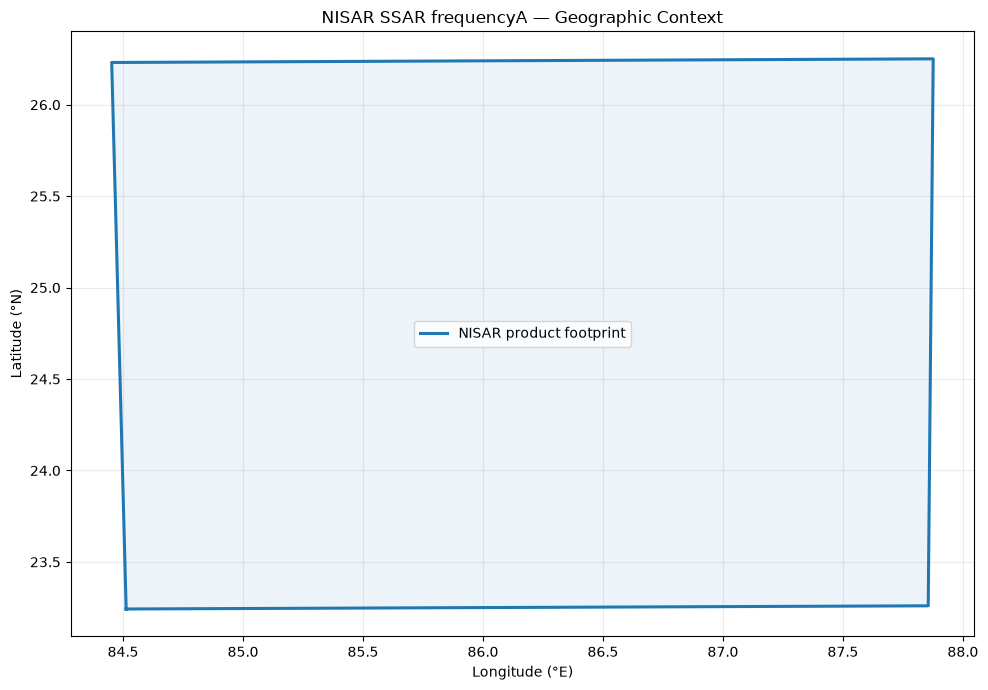

In [4]:
plot_scene_overview(_x,_y,profile.epsg,title=f"NISAR {profile.sar_family} {freq} — Geographic Context")


In [5]:
m=folium_scene_map(_x,_y,profile.epsg,title="NISAR scene — geographic context")
m


In [6]:
from nisar_utils.hdf5 import inspect_dataset
from nisar_utils.gcov import open_gcov

with open_gcov(NISAR_FILE) as f:
    for this_freq in profile.frequencies:
        print("\nFREQUENCY:", this_freq)
        for term in profile.covariance_terms.get(this_freq, []):
            path=f"{profile.gcov_root}/grids/{this_freq}/{term}"
            info=inspect_dataset(f,path)
            print("Summary:",term,info["shape"],info["dtype"],
                  "chunks=",info["chunks"],"compression=",info["compression"])



FREQUENCY: frequencyA
Dataset: /science/SSAR/GCOV/grids/frequencyA/HHHH
Shape: (33120, 34200)
Datatype: float32
Chunks: (512, 512)
Compression: gzip
Compression options: 1

Attributes:
  DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
  _FillValue: nan
  description: b'Covariance between HH and HH in Gamma0'
  grid_mapping: b'projection'
  long_name: b'radar backscatter gamma0'
  max_value: 6517.15625
  mean_value: 0.171357
  min_value: 0.00012
  sample_stddev: 1.071303
  units: b'DN'
  valid_max: nan
  valid_min: 0.0
Summary: HHHH (33120, 34200) float32 chunks= (512, 512) compression= gzip
Dataset: /science/SSAR/GCOV/grids/frequencyA/HHHV
Shape: (33120, 34200)
Datatype: complex64
Chunks: (512, 512)
Compression: gzip
Compression options: 1

Attributes:
  DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
  _FillValue: nan
  description: b'Covariance between HH

In [7]:
print("\nPolarization code:", profile.polarization_code)
print("Channels:", profile.polarization_channels)
print("\nModule 04 STATUS: PASS")



Polarization code: DHNA
Channels: ['HH', 'HV']

Module 04 STATUS: PASS


In [8]:
from pathlib import Path

print("CURRENT DIRECTORY:", Path.cwd())

print("\nFILES AND FOLDERS IN CURRENT DIRECTORY:")
for item in Path.cwd().iterdir():
    print(item.name)

print("\nSEARCHING FOR nisar_utils:")
for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / "nisar_utils"
    if candidate.exists():
        print("FOUND:", candidate)

CURRENT DIRECTORY: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\notebooks

FILES AND FOLDERS IN CURRENT DIRECTORY:
.ipynb_checkpoints
01_Setup_and_Product_Selection.ipynb
01_Setup_and_Product_Selection.ipynb.bak
02_Session_Check_and_Product_Orientation.ipynb
02_Session_Check_and_Product_Orientation.ipynb.bak
03_NISAR_L1_Product_Explorer_Metadata_First.ipynb
04_NISAR_L2_GCOV_Product_Explorer.ipynb
05_Large_NISAR_Data_Performance_and_Windowed_Access.ipynb
06_L2_GCOV_Spatial_Subsetting_AOI_LATLON_DEFAULT.ipynb
07_L2_GCOV_Quality_Control_Statistics_and_Masks.ipynb
08_L2_GCOV_Visualization_RGB_GCS.ipynb
09_Advanced_L2_GCOV_Frequency_Masks_Metadata_and_Batch_Processing.ipynb
10_L2_GCOV_GeoTIFF_Export_and_QGIS_Validation.ipynb
11_End_to_End_NISAR_L2_GCOV_Capstone.ipynb
12_Trainer_Troubleshooting_Performance_and_Session_Management.ipynb
13_Polarimetric_Mode_Discovery_and_Complex_Covariance_Inventory.ipynb
14_LSAR_FullPol_Complex_Covariance_Reconstruction_and_Validation

In [9]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("Package exists:", (ROOT / "nisar_utils").exists())

Project root: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training
Package exists: True
